In [1]:
!pip install -q "monai[nibabel,tqdm]" pydicom highdicom SimpleITK
import torch, monai
print(torch.cuda.is_available(), monai.__version__)

True 1.6.1


In [3]:
import os
os.makedirs("/kaggle/working/data", exist_ok=True)

from monai.apps import DecathlonDataset
ds = DecathlonDataset(root_dir="/kaggle/working/data", task="Task09_Spleen",
                      section="training", download=True, transform=None)
print(len(ds))

Task09_Spleen.tar: 1.50GB [00:45, 35.7MB/s]                               


2026-10-25 14:27:14,513 - INFO - Verified 'Task09_Spleen.tar', md5: 410d4a301da4e5b2f6f86ec3ddba524e.
2026-10-25 14:27:15,305 - INFO - Downloaded: /kaggle/working/data/Task09_Spleen.tar
2026-10-25 14:27:15,306 - INFO - Writing into directory: /kaggle/working/data.


Loading dataset: 100%|██████████| 33/33 [00:00<00:00, 140949.12it/s]

33


(512, 512, 55) (np.float32(0.976562), np.float32(0.976562), np.float32(5.0))


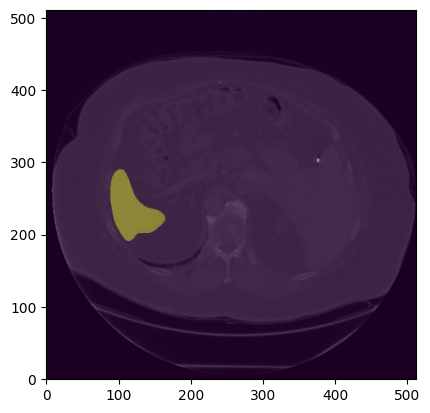

In [4]:
import nibabel as nib, matplotlib.pyplot as plt, glob
img_path = sorted(glob.glob("/kaggle/working/data/Task09_Spleen/imagesTr/*.nii.gz"))[0]
lbl_path = img_path.replace("imagesTr", "labelsTr")
img, lbl = nib.load(img_path), nib.load(lbl_path)
print(img.shape, img.header.get_zooms())
i = img.shape[2] // 2
plt.imshow(img.get_fdata()[:, :, i].T, cmap="gray", origin="lower")
plt.imshow(lbl.get_fdata()[:, :, i].T, alpha=0.4, origin="lower")
plt.show()